## **Cryptocurrency Market Analysis — Exploratory Data Analysis (EDA)**

### 1. Introduction
Cryptocurrency markets operate continuously and prices can change rapidly. This project uses **Yahoo Finance data through the `yfinance` Python library** to explore historical prices, returns, trading volume, and risk across selected cryptocurrencies.
The notebook combines data collection, cleaning, exploratory analysis, visualizations, and business-oriented questions. It is designed as a student portfolio project and can be adapted for a project presentation.
#### Project objectives
- Retrieve historical cryptocurrency market data from Yahoo Finance.
- Understand price trends and compare assets over time.
- Measure returns, volatility, and drawdowns.
- Explore relationships between cryptocurrencies and trading volume.
- Communicate findings with clear statistical summaries and charts.
#### Data source and limitations
- Library: `yfinance`
- Source: Yahoo Finance historical market data
- Example tickers:(`BTC-USD`),(`ETH-USD`),(`BNB-USD`),(`SOL-USD`),(`XRP-USD`),(`USDT-USD`)
- Yahoo Finance data availability, ticker support, and update frequency can change. This is historical market data fetched when the notebook runs; it is not a guaranteed real-time trading feed.
- This project is for educational analysis, not investment advice.
#### Main libraries
`yfinance`, `pandas`, `numpy`, `matplotlib`, and `seaborn`.


### 3. Install and import libraries


In [1]:

import warnings
warnings.filterwarnings("ignore")

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


### 4. Download cryptocurrency data

Change `START_DATE` and `END_DATE` to choose the analysis period. The example uses approximately the last year of daily data. `auto_adjust=True` adjusts OHLC prices for applicable corporate actions; crypto assets generally do not have stock-style dividends or splits, but this keeps the download interface consistent.


In [2]:
TICKERS = ["BTC-USD","ETH-USD","BNB-USD","SOL-USD","XRP-USD","USDT-USD"]
raw = yf.download(
    TICKERS,
    start="2024-01-01",
    end=None,
    interval="1d",
    auto_adjust=True
   
)
if raw.empty:
    raise RuntimeError(
        "No data was returned. Check your internet connection, date range, "
        "ticker symbols, and whether Yahoo Finance is responding."
    )
print("Downloaded data shape:", raw.shape)
display(raw.tail())

[*********************100%***********************]  6 of 6 completed


Downloaded data shape: (1027, 30)


Price            Close                                                   \
Ticker         BNB-USD       BTC-USD      ETH-USD     SOL-USD  USDT-USD   
Date                                                                      
2026-10-19  730.955383  81853.539062  2404.815186  104.926231  0.998820   
2026-10-20  740.823608  82941.000000  2446.730713  106.422340  0.998917   
2026-10-21  745.868347  84011.968750  2470.766113  106.793655  0.999195   
2026-10-22  730.476624  81311.890625  2386.189209  103.542320  0.998739   
2026-10-23  744.229980  81675.437500  2404.000000  104.550003  0.998560   

Price                       High                                         \
Ticker       XRP-USD     BNB-USD       BTC-USD      ETH-USD     SOL-USD   
Date                                                                      
2026-10-19  1.302713  732.592102  83072.468750  2443.556396  105.908302   
2026-10-20  1.334452  742.001221  83287.804688  2474.202637  108.009880   
2026-10-21  1.363619  750.822998  84840.046875  2522.841797  109.030388   
2026-10-22  1.307656  748.723572  84301.281250  2479.773926  107.342743   
2026-10-23  1.325300  745.665527  81891.007812  2412.922852  104.643295   

Price                                  Low                             \
Ticker      USDT-USD   XRP-USD     BNB-USD       BTC-USD      ETH-USD   
Date                                                                    
2026-10-19  0.999641  1.318128  721.721863  81668.218750  2383.531006   
2026-10-20  0.999527  1.342853  724.959961  81107.234375  2372.890381   
2026-10-21  0.999865  1.396630  739.447449  82543.445312  2434.962402   
2026-10-22  0.999664  1.367940  725.615051  80841.273438  2358.748535   
2026-10-23  0.999204  1.327514  729.617615  81046.804688  2381.623535   

Price                                             Open                \
Ticker         SOL-USD  USDT-USD   XRP-USD     BNB-USD       BTC-USD   
Date                                                                   
2026-10-19  103.604362  0.998564  1.294253  722.255371  82017.601562   
2026-10-20  103.708389  0.998438  1.287337  730.955383  81853.539062   
2026-10-21  105.563141  0.998512  1.330666  740.823608  82941.000000   
2026-10-22  103.009041  0.998496  1.296248  745.868347  84011.968750   
2026-10-23  103.411240  0.998474  1.306172  730.463501  81316.203125   

Price                                                        Volume  \
Ticker          ETH-USD     SOL-USD  USDT-USD   XRP-USD     BNB-USD   
Date                                                                  
2026-10-19  2408.741455  104.024689  0.998815  1.304955  1303855781   
2026-10-20  2404.815186  104.926231  0.998820  1.302713  1284997038   
2026-10-21  2446.730713  106.422340  0.998917  1.334452  1394660293   
2026-10-22  2470.766113  106.793655  0.999195  1.363619  1309458842   
2026-10-23  2386.287598  103.544296  0.998734  1.307685  1271859456   

Price                                                                      
Ticker          BTC-USD      ETH-USD     SOL-USD     USDT-USD     XRP-USD  
Date                                                                       
2026-10-19  24424961001   8636807435  2411852216  55785483354  1543369058  
2026-10-20  26999680268  11051978931  2706369186  61361777310  1805996012  
2026-10-21  30470182680  13271819478  2490313714  66367920070  2238710865  
2026-10-22  33451533824  12698935108  2429847895  66929918035  1850802328  
2026-10-23  26926116864  11943880704  2008246784  58154065920  1625917440

### 5. Prepare and inspect the data

`yfinance` may return columns with a MultiIndex when multiple tickers are requested. The following cell extracts the closing prices, high, low, and volume into separate DataFrames and checks missing values.


In [3]:
# Extract a field from yfinance output, supporting common column layouts
def extract_field(data, field, tickers):
    if isinstance(data.columns, pd.MultiIndex):
        level0 = data.columns.get_level_values(0)
        level1 = data.columns.get_level_values(1)

        if field in level0:
            result = data[field].copy()
        elif field in level1:
            result = data.xs(field, axis=1, level=1).copy()
        else:
            raise KeyError(f"Field {field!r} was not found in downloaded data.")
    else:
        if field not in data.columns:
            raise KeyError(f"Field {field!r} was not found in downloaded data.")
        result = data[[field]].copy()
        if len(tickers) == 1:
            result.columns = [tickers[0]]

    # Keep only available requested tickers, preserving their order
    available = [ticker for ticker in tickers if ticker in result.columns]
    return result[available].sort_index()

close = extract_field(raw, "Close", TICKERS)
high = extract_field(raw, "High", TICKERS)
low = extract_field(raw, "Low", TICKERS)
volume = extract_field(raw, "Volume", TICKERS)

# Use assets for which closing prices were returned
available_tickers = [c for c in close.columns if close[c].notna().any()]
close = close[available_tickers].dropna(how="all")
high = high.reindex(columns=available_tickers)
low = low.reindex(columns=available_tickers)
volume = volume.reindex(columns=available_tickers)

print("Available tickers:", available_tickers)
print("Date range:", close.index.min().date(), "to", close.index.max().date())
display(close.tail())
display(close.describe().T)

Available tickers: ['BTC-USD', 'ETH-USD', 'BNB-USD', 'SOL-USD', 'XRP-USD', 'USDT-USD']
Date range: 2024-01-01 to 2026-10-23


Ticker,BTC-USD,ETH-USD,BNB-USD,SOL-USD,XRP-USD,USDT-USD
Date,,,,,,
2026-10-19,81853.539062,2404.815186,730.955383,104.926231,1.302713,0.998820
2026-10-20,82941.000000,2446.730713,740.823608,106.422340,1.334452,0.998917
2026-10-21,84011.968750,2470.766113,745.868347,106.793655,1.363619,0.999195
2026-10-22,81311.890625,2386.189209,730.476624,103.542320,1.307656,0.998739
2026-10-23,81675.437500,2404.000000,744.229980,104.550003,1.325300,0.998560


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
BTC-USD,1027.0,80921.487334,19912.794711,39507.367188,64760.955078,78214.484375,96555.902344,124752.531250
ETH-USD,1027.0,2817.721982,740.601621,1472.553101,2290.326904,2665.712158,3334.201050,4831.348633
BNB-USD,1027.0,661.764443,164.110394,291.919281,581.120850,625.898071,720.610199,1310.214355
SOL-USD,1027.0,142.379671,45.750990,62.189804,102.891270,141.798508,174.305801,261.869751
XRP-USD,1027.0,1.547503,0.856647,0.419823,0.597871,1.409206,2.253623,3.555765
USDT-USD,1027.0,0.999843,0.000598,0.997843,0.999515,0.999911,1.000227,1.002224


In [4]:
# Missing-value overview
missing = close.isna().sum().sort_values(ascending=False)
missing_df = missing.rename("missing_close_values").to_frame()
display(missing_df)

# Forward-fill only small gaps for price-series comparisons; do not fill leading gaps
close = close.ffill()
returns = close.pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan)
daily_returns = returns.dropna(how="all")

print("Closing-price dataset shape:", close.shape)
print("Daily-returns dataset shape:", daily_returns.shape)

,missing_close_values
Ticker,
BTC-USD,0
ETH-USD,0
BNB-USD,0
SOL-USD,0
XRP-USD,0
USDT-USD,0


Closing-price dataset shape: (1027, 6)
Daily-returns dataset shape: (1026, 6)


## 6. Business Question 

### How have closing prices changed over time?

A line chart helps compare price trends. Since coins trade at very different price levels, the next chart uses a separate line for each asset on its original price scale. The indexed chart later compares performance from a common starting value.

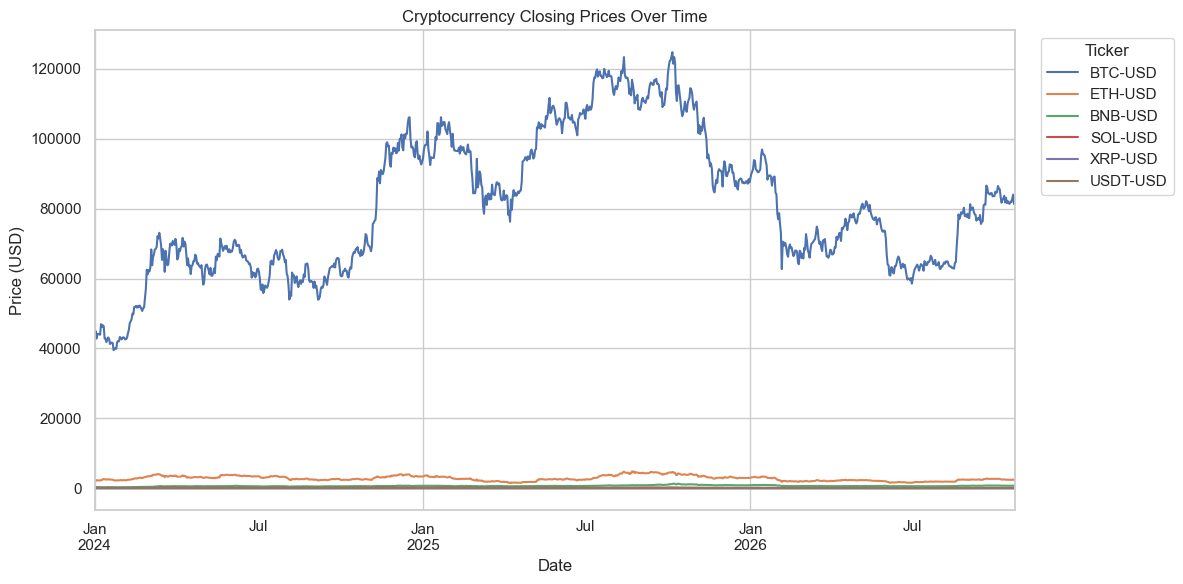

In [5]:
close.plot(linewidth=1.5)
plt.title("Cryptocurrency Closing Prices Over Time")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend(title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Which cryptocurrency has the highest latest closing price?

This ranks the latest available closing price for each downloaded asset. A higher nominal price does not mean an asset is more valuable overall; market capitalization and supply also matter.


,Latest close (USD)
Ticker,
BTC-USD,81675.437500
ETH-USD,2404.000000
BNB-USD,744.229980
SOL-USD,104.550003
XRP-USD,1.325300
USDT-USD,0.998560


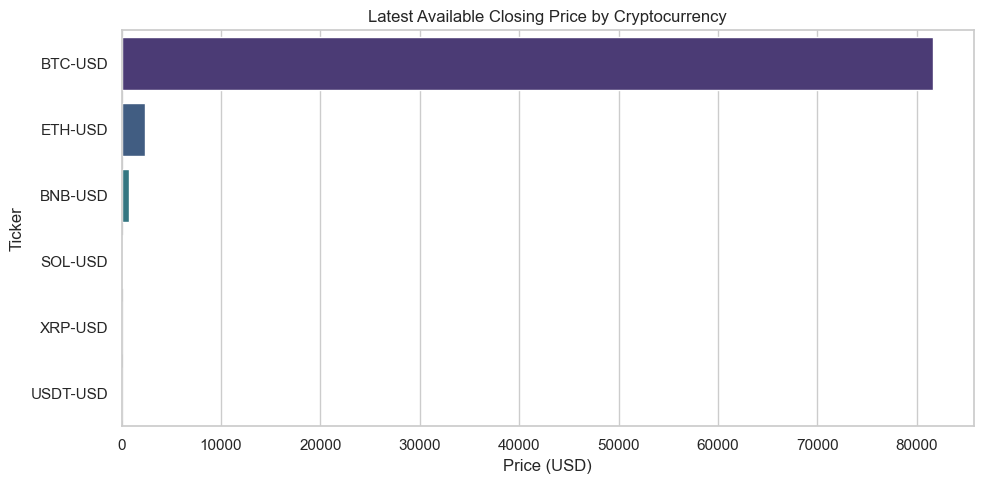

In [6]:
latest_prices = close.ffill().iloc[-1].dropna().sort_values(ascending=False)
display(latest_prices.rename("Latest close (USD)").to_frame())

plt.figure(figsize=(10, 5))
sns.barplot(x=latest_prices.values, y=latest_prices.index, hue=latest_prices.index,
            palette="viridis", legend=False)
plt.title("Latest Available Closing Price by Cryptocurrency")
plt.xlabel("Price (USD)")
plt.ylabel("Ticker")
plt.tight_layout()
plt.show()

### Which cryptocurrency had the highest cumulative return?

Cumulative return measures the percentage change from the first available close to the last available close in the selected period.


,Cumulative return (%)
Ticker,
BNB-USD,136.708125
XRP-USD,110.337695
BTC-USD,84.922733
ETH-USD,2.196638
USDT-USD,-0.180732
SOL-USD,-4.528115


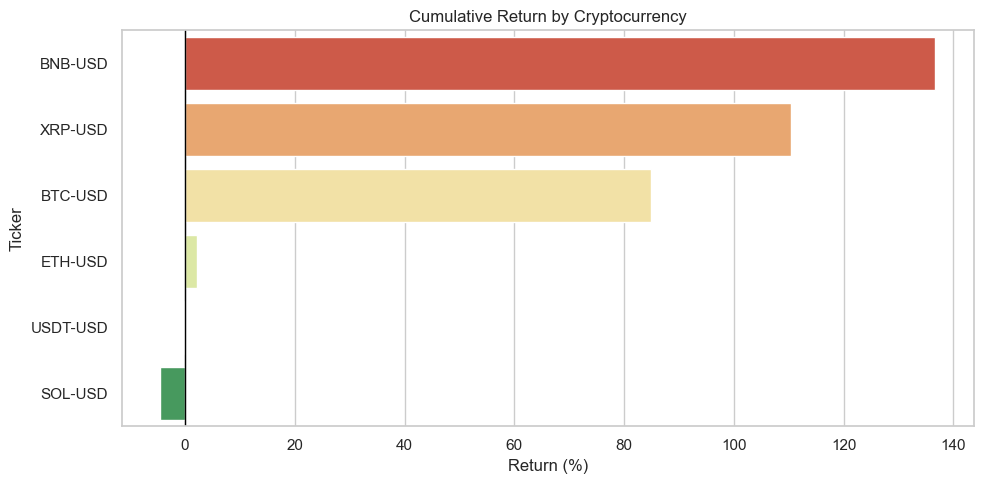

In [7]:
cumulative_return = (close.ffill().iloc[-1] / close.ffill().iloc[0] - 1).dropna()
cumulative_return = cumulative_return.sort_values(ascending=False)
display((cumulative_return * 100).rename("Cumulative return (%)").to_frame())

plt.figure(figsize=(10, 5))
sns.barplot(x=cumulative_return.values * 100, y=cumulative_return.index,
            hue=cumulative_return.index, palette="RdYlGn", legend=False)
plt.axvline(0, color="black", linewidth=1)
plt.title("Cumulative Return by Cryptocurrency")
plt.xlabel("Return (%)")
plt.ylabel("Ticker")
plt.tight_layout()
plt.show()

### Which cryptocurrency had the highest average daily return?

Daily returns show percentage changes from one close to the next. The mean daily return is descriptive and can be strongly affected by outliers.

,Mean daily return (%)
Ticker,
XRP-USD,0.155458
BNB-USD,0.121266
BTC-USD,0.090295
SOL-USD,0.079216
ETH-USD,0.064218
USDT-USD,-0.000171


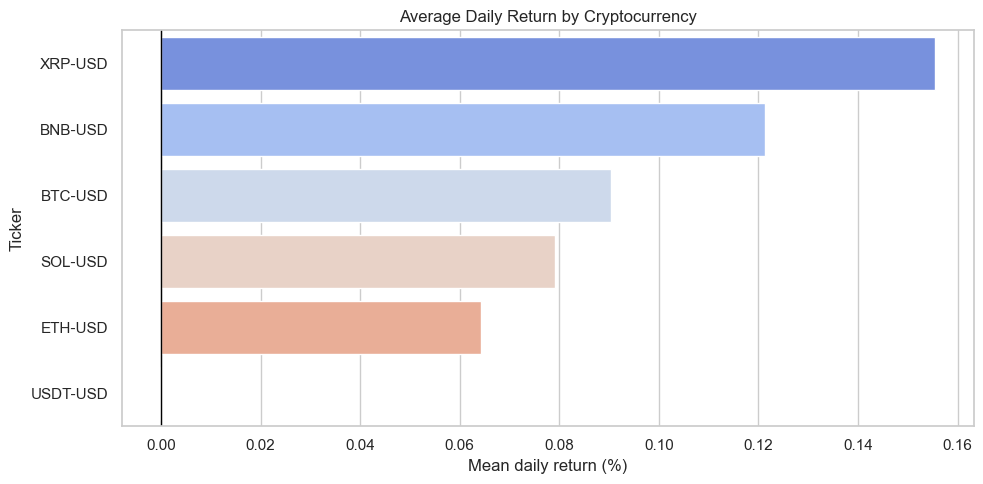

In [8]:
mean_daily_return = daily_returns.mean().dropna().sort_values(ascending=False)
display((mean_daily_return * 100).rename("Mean daily return (%)").to_frame())

plt.figure(figsize=(10, 5))
sns.barplot(x=mean_daily_return.values * 100, y=mean_daily_return.index,
            hue=mean_daily_return.index, palette="coolwarm", legend=False)
plt.axvline(0, color="black", linewidth=1)
plt.title("Average Daily Return by Cryptocurrency")
plt.xlabel("Mean daily return (%)")
plt.ylabel("Ticker")
plt.tight_layout()
plt.show()

### Which cryptocurrency was the most volatile?

Volatility is measured here as the standard deviation of daily percentage returns. Annualized volatility multiplies daily standard deviation by the square root of 365 because cryptocurrency markets trade every day. It is an estimate, not a forecast.


,Daily volatility (%),Annualized volatility (%)
Ticker,,
XRP-USD,4.137956,79.055537
SOL-USD,4.102742,78.382768
ETH-USD,3.545247,67.731851
BNB-USD,2.740454,52.356307
BTC-USD,2.471054,47.209424
USDT-USD,0.033511,0.640225


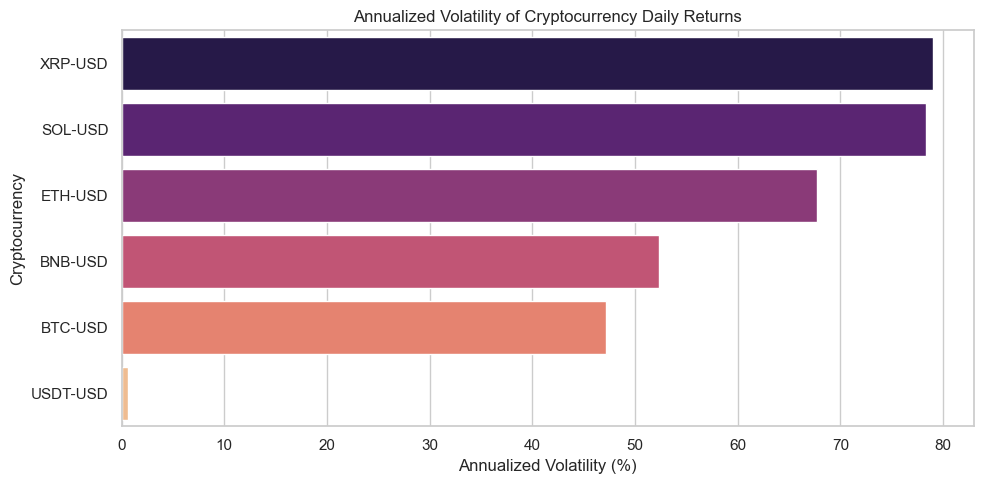

In [9]:

daily_volatility = daily_returns.std()
annualized_volatility = daily_volatility * np.sqrt(365)
volatility_table = pd.DataFrame({
    "Daily volatility (%)": daily_volatility * 100,
    "Annualized volatility (%)": annualized_volatility * 100
})
volatility_table.index.name = "Ticker"
volatility_table = volatility_table.sort_values(
    "Annualized volatility (%)",
    ascending=False
)
display(volatility_table)
# Convert the index into a column named Ticker
plot_data = volatility_table.reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(
    data=plot_data,
    x="Annualized volatility (%)",
    y="Ticker",
    hue="Ticker",
    palette="magma",
    legend=False
)
plt.title("Annualized Volatility of Cryptocurrency Daily Returns")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Cryptocurrency")
plt.tight_layout()
plt.show()


### What is the distribution of daily returns?

Histograms reveal the spread and skew of daily returns. Extreme values can be important in cryptocurrency risk analysis.


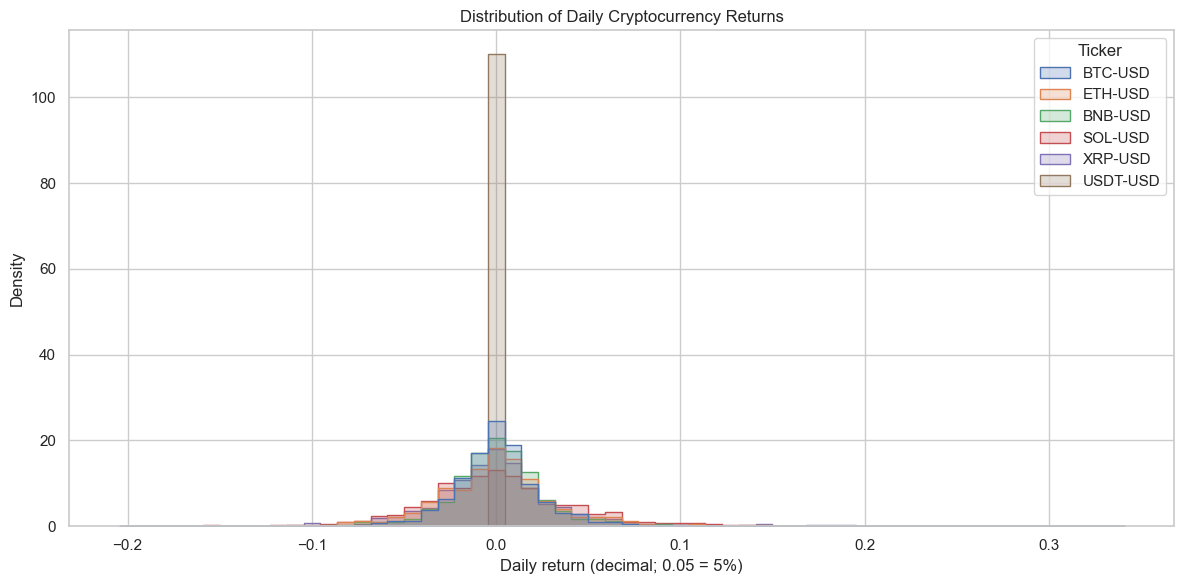

In [10]:
returns_long = daily_returns.rename_axis("Date").reset_index().melt(
    id_vars="Date", var_name="Ticker", value_name="Daily Return"
).dropna()

plt.figure(figsize=(12, 6))
sns.histplot(data=returns_long, x="Daily Return", hue="Ticker",
             element="step", stat="density", common_norm=False,
             bins=60, alpha=0.25)
plt.title("Distribution of Daily Cryptocurrency Returns")
plt.xlabel("Daily return (decimal; 0.05 = 5%)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

### How strongly are daily returns correlated?

Correlation ranges from -1 to +1. Positive values indicate returns tend to move in the same direction; negative values indicate opposite movement. Correlation does not prove causation.


Ticker,BTC-USD,ETH-USD,BNB-USD,SOL-USD,XRP-USD,USDT-USD
Ticker,,,,,,
BTC-USD,1.000,0.821,0.681,0.782,0.648,0.353
ETH-USD,0.821,1.000,0.684,0.774,0.642,0.245
BNB-USD,0.681,0.684,1.000,0.653,0.499,0.205
SOL-USD,0.782,0.774,0.653,1.000,0.634,0.246
XRP-USD,0.648,0.642,0.499,0.634,1.000,0.170
USDT-USD,0.353,0.245,0.205,0.246,0.170,1.000


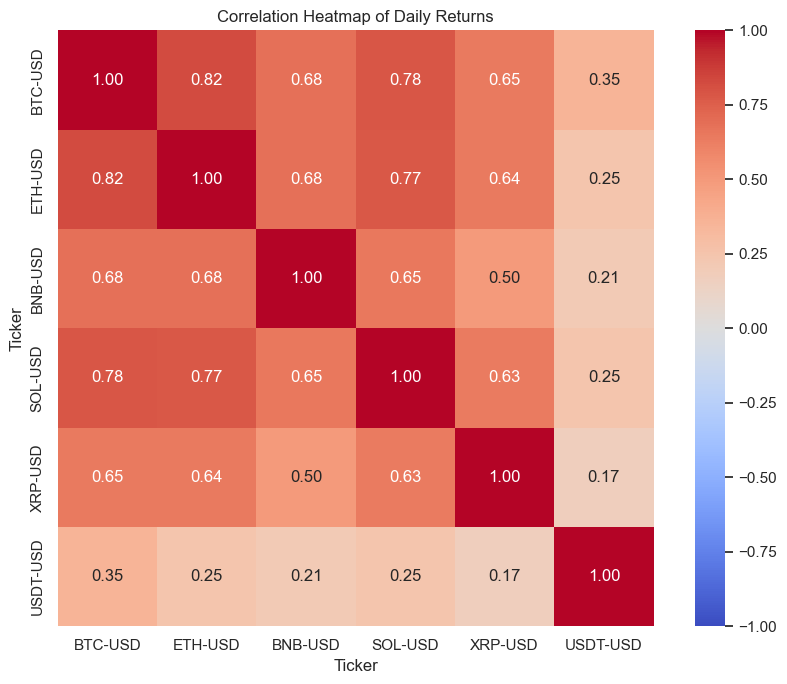

In [11]:
corr = daily_returns.corr()
display(corr.round(3))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True)
plt.title("Correlation Heatmap of Daily Returns")
plt.tight_layout()
plt.show()

### Does trading volume vary alongside price movements?

This scatter plot compares absolute daily returns with daily trading volume. Volume scales differ substantially between assets, so points are shown by ticker. Because volume can be highly skewed, the x-axis uses a logarithmic scale where positive observations are available.

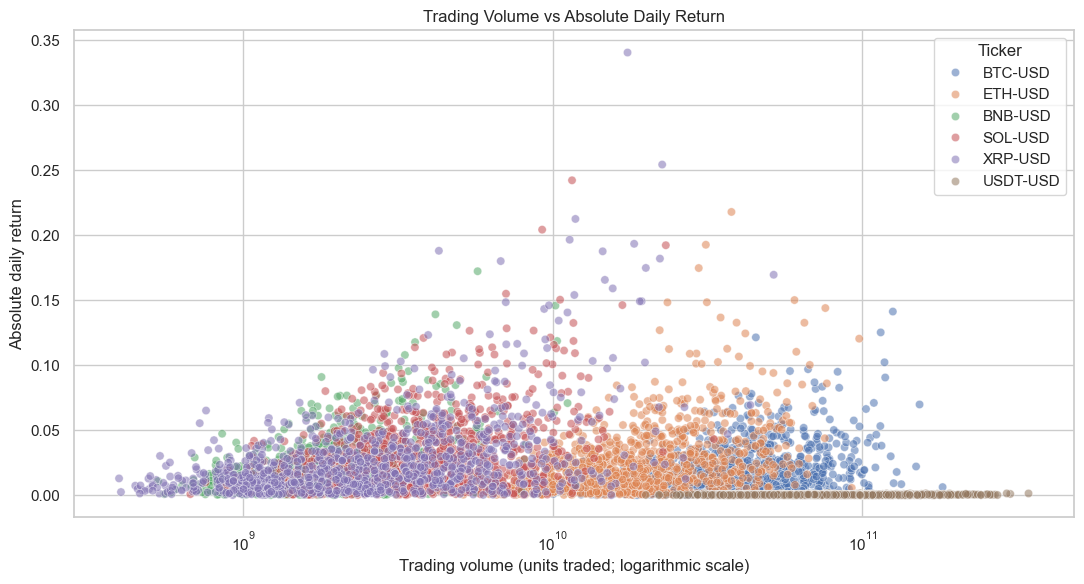

In [12]:
volume_clean = volume.reindex(daily_returns.index)
volume_long = volume_clean.rename_axis("Date").reset_index().melt(
    id_vars="Date", var_name="Ticker", value_name="Volume"
)
abs_returns_long = daily_returns.abs().rename_axis("Date").reset_index().melt(
    id_vars="Date", var_name="Ticker", value_name="Absolute Return"
)
volume_returns = volume_long.merge(abs_returns_long, on=["Date", "Ticker"]).dropna()
volume_returns = volume_returns[(volume_returns["Volume"] > 0) & (volume_returns["Absolute Return"].notna())]

plt.figure(figsize=(11, 6))
sns.scatterplot(data=volume_returns, x="Volume", y="Absolute Return",
                hue="Ticker", alpha=0.55)
plt.xscale("log")
plt.title("Trading Volume vs Absolute Daily Return")
plt.xlabel("Trading volume (units traded; logarithmic scale)")
plt.ylabel("Absolute daily return")
plt.tight_layout()
plt.show()

### Which cryptocurrency had the largest single-day loss and gain?

The following table identifies the largest daily return and the largest daily loss for each asset, then summarizes the most extreme observations in the sample.


In [13]:
extreme_returns = pd.DataFrame({
    "Best daily return (%)": daily_returns.max() * 100,
    "Worst daily return (%)": daily_returns.min() * 100
})
display(extreme_returns.sort_values("Best daily return (%)", ascending=False))

best = daily_returns.stack().idxmax()
worst = daily_returns.stack().idxmin()
print(f"Largest gain: {best[1]} on {best[0].date()} ({daily_returns.loc[best] * 100:.2f}%)")
print(f"Largest loss: {worst[1]} on {worst[0].date()} ({daily_returns.loc[worst] * 100:.2f}%)")

,Best daily return (%),Worst daily return (%)
Ticker,,
XRP-USD,34.070029,-19.659696
SOL-USD,24.234991,-20.434359
ETH-USD,21.798769,-15.013782
BNB-USD,17.233970,-13.085530
BTC-USD,12.524769,-14.129892
USDT-USD,0.149824,-0.134469


Largest gain: XRP-USD on 2025-03-02 (34.07%)
Largest loss: SOL-USD on 2025-03-03 (-20.43%)


### How do daily trading volumes compare?

Trading volume is the number of units traded during a period. The chart uses average daily volume for each asset. Since tokens have different units and supply, raw volume is not directly comparable as a measure of market value.

,Average daily volume (units)
Ticker,
USDT-USD,8.555428e+10
BTC-USD,4.208632e+10
ETH-USD,2.173454e+10
SOL-USD,4.263797e+09
XRP-USD,3.843217e+09
BNB-USD,2.001982e+09


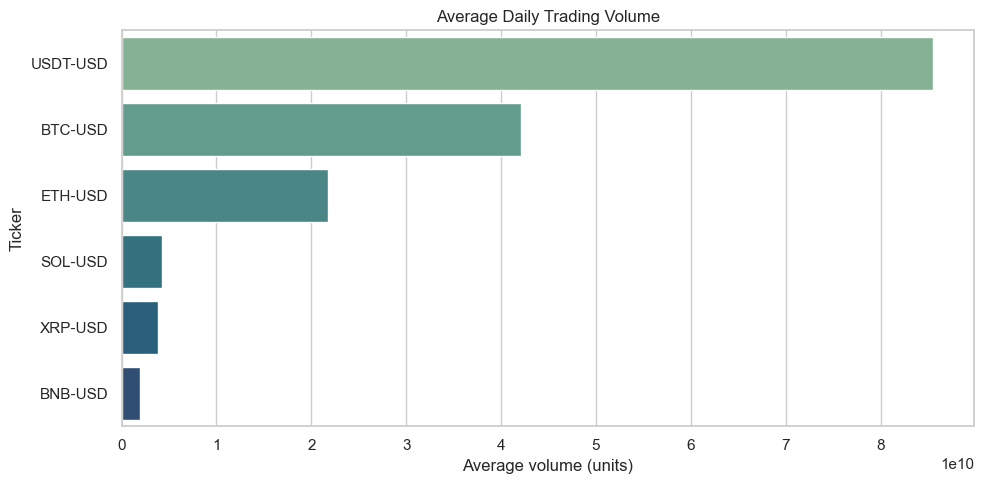

In [14]:
avg_volume = volume.mean().dropna().sort_values(ascending=False)
display(avg_volume.rename("Average daily volume (units)").to_frame())

plt.figure(figsize=(10, 5))
sns.barplot(x=avg_volume.values, y=avg_volume.index, hue=avg_volume.index,
            palette="crest", legend=False)
plt.title("Average Daily Trading Volume")
plt.xlabel("Average volume (units)")
plt.ylabel("Ticker")
plt.tight_layout()
plt.show()

### What are the high-low price ranges?

This box plot shows the distribution of the daily percentage range `(High - Low) / Close`. It compares relative intraday ranges rather than raw USD ranges, making assets with different price levels easier to compare.


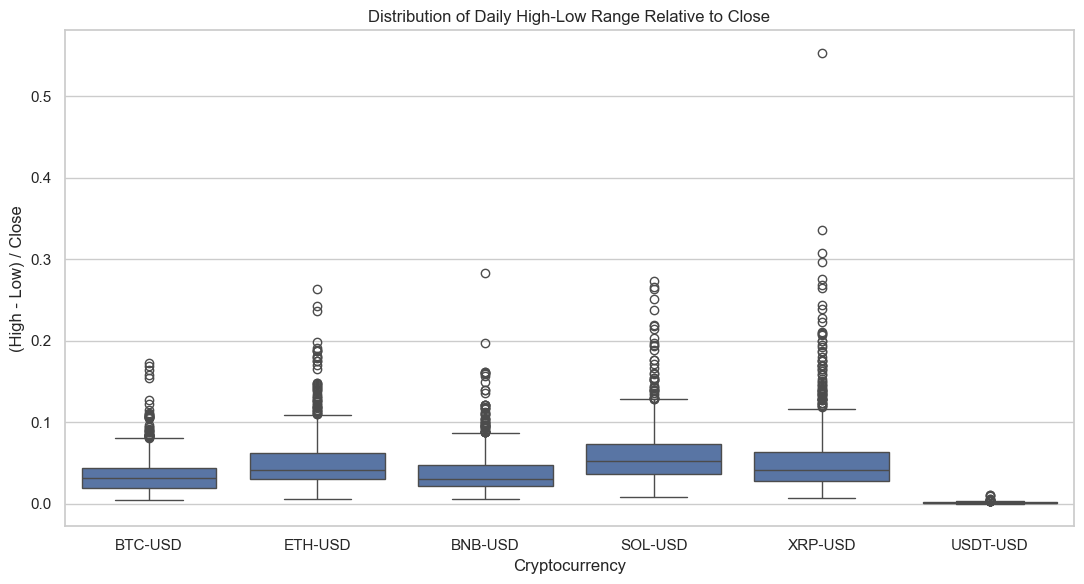

In [15]:
relative_range = ((high - low) / close).replace([np.inf, -np.inf], np.nan)
range_long = relative_range.rename_axis("Date").reset_index().melt(
    id_vars="Date", var_name="Ticker", value_name="Relative Range"
).dropna()

plt.figure(figsize=(11, 6))
sns.boxplot(data=range_long, x="Ticker", y="Relative Range")
plt.title("Distribution of Daily High-Low Range Relative to Close")
plt.xlabel("Cryptocurrency")
plt.ylabel("(High - Low) / Close")
plt.tight_layout()
plt.show()

### How would a hypothetical $1,000 investment have performed?

Each asset is indexed to the same starting investment amount. This is a simplified comparison and excludes fees, taxes, slippage, and execution timing.


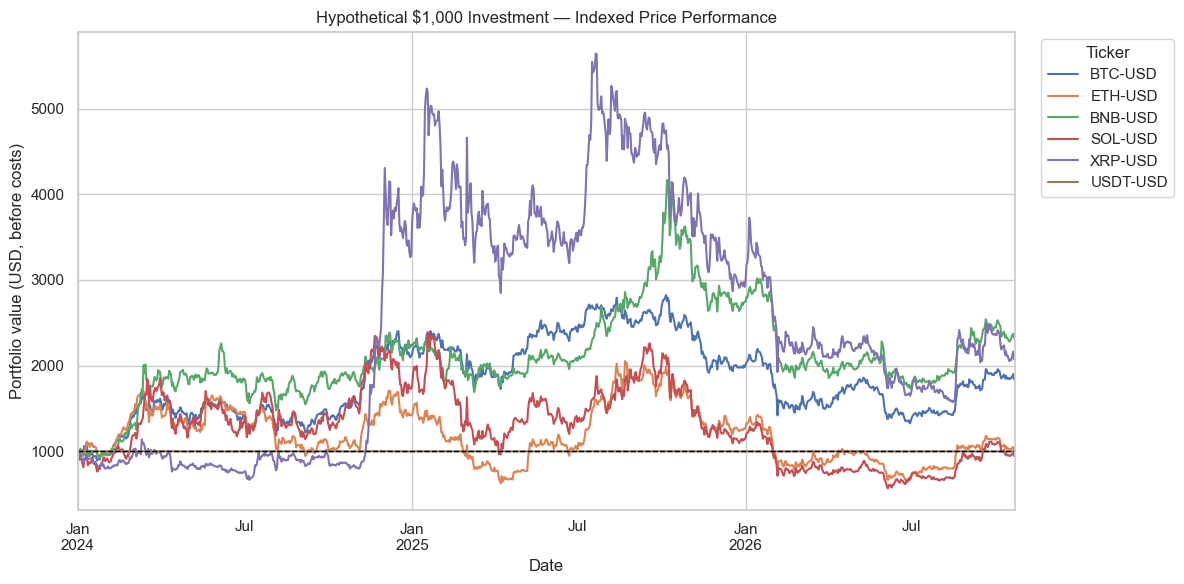

,Ending value ($)
Ticker,
BNB-USD,2367.081254
XRP-USD,2103.376949
BTC-USD,1849.227330
ETH-USD,1021.966376
USDT-USD,998.192677
SOL-USD,954.718849


In [16]:
investment_value = close.div(close.ffill().iloc[0]).mul(1000)
investment_value = investment_value.dropna(how="all")

investment_value.plot(linewidth=1.5)
plt.axhline(1000, color="black", linestyle="--", linewidth=1)
plt.title("Hypothetical $1,000 Investment — Indexed Price Performance")
plt.xlabel("Date")
plt.ylabel("Portfolio value (USD, before costs)")
plt.legend(title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(investment_value.iloc[-1].rename("Ending value ($)").to_frame().sort_values("Ending value ($)", ascending=False))

### What was the maximum drawdown?

Drawdown measures the fall from a previous running peak. Maximum drawdown is the largest peak-to-trough decline in the selected period and is one way to describe historical downside risk.


,Maximum drawdown (%)
Ticker,
SOL-USD,-76.251627
XRP-USD,-72.102403
ETH-USD,-67.611183
BNB-USD,-58.351383
BTC-USD,-53.059983
USDT-USD,-0.437122


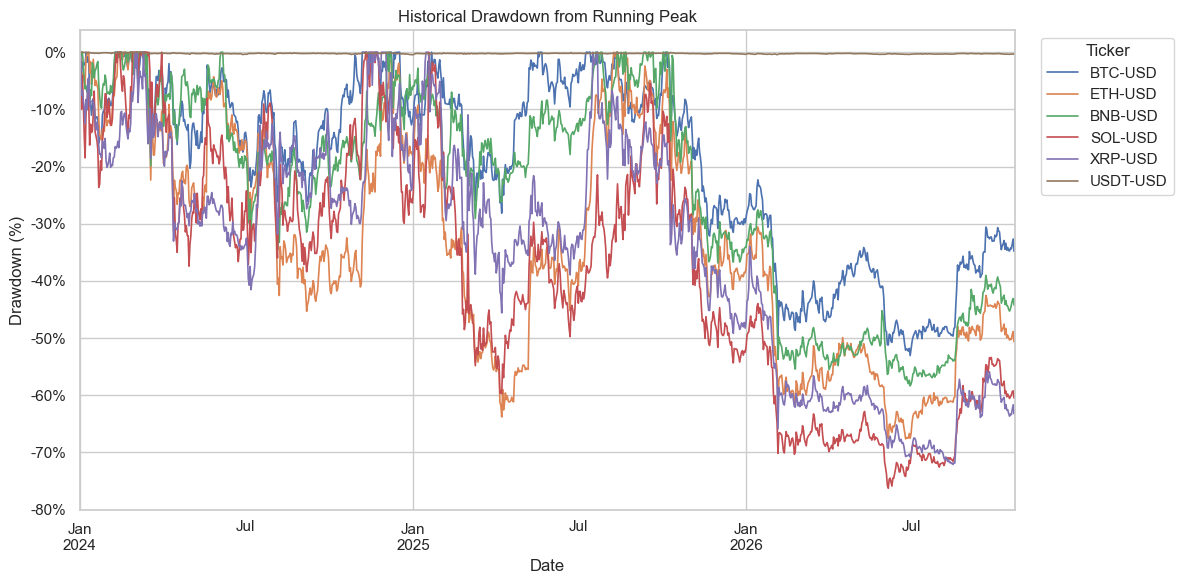

In [17]:
running_peak = close.cummax()
drawdown = close / running_peak - 1
max_drawdown = drawdown.min().sort_values()
display((max_drawdown * 100).rename("Maximum drawdown (%)").to_frame())

drawdown.plot(linewidth=1.2)
plt.title("Historical Drawdown from Running Peak")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.legend(title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Which cryptocurrency showed the strongest return relative to volatility?

A simple descriptive risk-adjusted metric is mean daily return divided by daily standard deviation. This is **not** a conventional annualized Sharpe ratio because no risk-free rate is included and the result is not annualized. Ratios can be unstable when the average return is near zero.


,Cumulative return (%),Mean daily return (%),Daily volatility (%),Maximum drawdown (%),Mean-return / volatility ratio
Ticker,,,,,
BNB-USD,136.708,0.121,2.740,-58.351,0.044
XRP-USD,110.338,0.155,4.138,-72.102,0.038
BTC-USD,84.923,0.090,2.471,-53.060,0.037
SOL-USD,-4.528,0.079,4.103,-76.252,0.019
ETH-USD,2.197,0.064,3.545,-67.611,0.018
USDT-USD,-0.181,-0.000,0.034,-0.437,-0.005


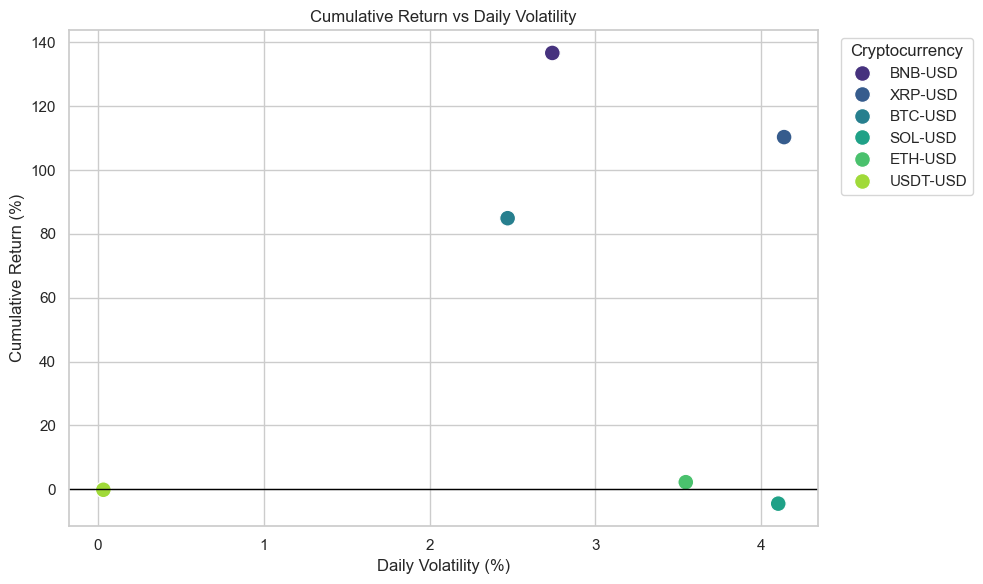

In [18]:

risk_summary = pd.DataFrame({
    "Cumulative return (%)":
        (close.ffill().iloc[-1] / close.ffill().iloc[0] - 1) * 100,
    "Mean daily return (%)": daily_returns.mean() * 100,
    "Daily volatility (%)": daily_returns.std() * 100,
    "Maximum drawdown (%)": drawdown.min() * 100,
    "Mean-return / volatility ratio":
        daily_returns.mean() / daily_returns.std()
}).sort_values(
    "Mean-return / volatility ratio",
    ascending=False
)
display(risk_summary.round(3))
# Give the index a meaningful name before converting it to a column
risk_summary.index.name = "Ticker"
plot_data = risk_summary.reset_index()
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_data,
    x="Daily volatility (%)",
    y="Cumulative return (%)",
    hue="Ticker",
    s=130,
    palette="viridis"
)
plt.axhline(0, color="black", linewidth=1)
plt.title("Cumulative Return vs Daily Volatility")
plt.xlabel("Daily Volatility (%)")
plt.ylabel("Cumulative Return (%)")
plt.legend(
    title="Cryptocurrency",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


## 7. Candlestick-style OHLC view

The chart below uses daily high, low, open, and close values for Bitcoin, when available. It displays a recent subset of observations to keep the figure readable. This is a simple Matplotlib rendering, not a full technical-trading chart.

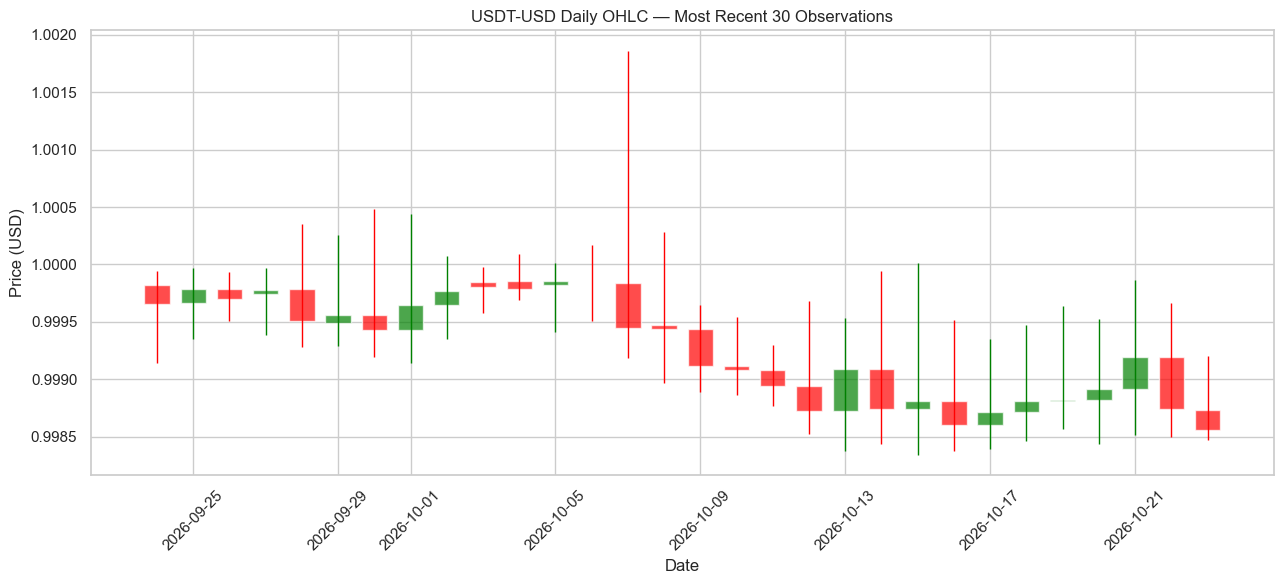

In [22]:
# Extract Open for the first available ticker (prefer BTC-USD if downloaded)
ohlc_ticker = "USDT-USD" if "USDT-USD" in available_tickers else available_tickers[0]
open_prices = extract_field(raw, "Open", TICKERS).reindex(columns=[ohlc_ticker])[ohlc_ticker]
ohlc = pd.DataFrame({
    "Open": open_prices,
    "High": high[ohlc_ticker],
    "Low": low[ohlc_ticker],
    "Close": close[ohlc_ticker]
}).dropna().tail(30)

fig, ax = plt.subplots(figsize=(13, 6))
for date, row in ohlc.iterrows():
    up = row["Close"] >= row["Open"]
    color = "green" if up else "red"
    ax.vlines(date, row["Low"], row["High"], color=color, linewidth=1)
    bottom = min(row["Open"], row["Close"])
    height = abs(row["Close"] - row["Open"])
    if height == 0:
        height = max(row["Close"] * 0.001, 0.01)
    ax.bar(date, height, bottom=bottom, width=0.7, color=color, alpha=0.7)

ax.set_title(f"{ohlc_ticker} Daily OHLC — Most Recent 30 Observations")
ax.set_xlabel("Date")
ax.set_ylabel("Price (USD)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Key findings summary

The following code generates a compact summary from the data fetched in this run. Use the values as evidence for your project report rather than assuming any coin is always the best performer.

In [20]:
summary = pd.DataFrame({
    "Latest close (USD)": close.ffill().iloc[-1],
    "Cumulative return (%)": (close.ffill().iloc[-1] / close.ffill().iloc[0] - 1) * 100,
    "Annualized volatility (%)": daily_returns.std() * np.sqrt(365) * 100,
    "Maximum drawdown (%)": drawdown.min() * 100,
    "Average daily volume": volume.mean()
}).sort_values("Cumulative return (%)", ascending=False)

display(summary.round(3))

print("Best cumulative performer in this sample:",
      summary["Cumulative return (%)"].idxmax())
print("Highest annualized volatility in this sample:",
      summary["Annualized volatility (%)"].idxmax())
print("Largest maximum drawdown in this sample:",
      summary["Maximum drawdown (%)"].idxmin())

,Latest close (USD),Cumulative return (%),Annualized volatility (%),Maximum drawdown (%),Average daily volume
Ticker,,,,,
BNB-USD,744.230,136.708,52.356,-58.351,2.001982e+09
XRP-USD,1.325,110.338,79.056,-72.102,3.843217e+09
BTC-USD,81675.438,84.923,47.209,-53.060,4.208632e+10
ETH-USD,2404.000,2.197,67.732,-67.611,2.173454e+10
USDT-USD,0.999,-0.181,0.640,-0.437,8.555428e+10
SOL-USD,104.550,-4.528,78.383,-76.252,4.263797e+09


Best cumulative performer in this sample: BNB-USD
Highest annualized volatility in this sample: XRP-USD
Largest maximum drawdown in this sample: SOL-USD


## 9. Export the cleaned datasets

Save the prices, returns, and summary table for documentation or further analysis. Files will be saved to the current notebook working directory.


In [21]:
close.to_csv("crypto_closing_prices.csv", index_label="Date")
daily_returns.to_csv("crypto_daily_returns.csv", index_label="Date")
summary.to_csv("crypto_eda_summary.csv", index_label="Ticker")

print("Saved: crypto_closing_prices.csv")
print("Saved: crypto_daily_returns.csv")
print("Saved: crypto_eda_summary.csv")

Saved: crypto_closing_prices.csv
Saved: crypto_daily_returns.csv
Saved: crypto_eda_summary.csv


## 10. Conclusion

This EDA workflow compares selected cryptocurrencies using Yahoo Finance data accessed through `yfinance`. It examines price history, returns, volatility, correlations, volume, relative price ranges, hypothetical investment growth, and drawdowns.

### Conclusion points
- Identify the strongest and weakest cumulative performers during the selected sample.
- Compare historical volatility with cumulative return.
- Discuss whether assets moved together based on the return-correlation heatmap.
- Explain how maximum drawdown changes the interpretation of headline returns.
- State limitations: sample period, selected tickers, missing observations, data-provider availability, and exclusion of transaction costs.

### Future improvements
- Add more ticker symbols and compare different time periods.
- Build a Streamlit dashboard that refreshes on demand.
- Collect scheduled snapshots to create a separate intraday dataset.
- Add a benchmark comparison and a carefully defined risk-adjusted performance metric.